# 08: Success Metrics for All Models (Task 3)

Compare the logistic regression (04), gradient boosting (05), and random forest (06) models on the same held-out test set with one shared set of metrics.

**Input:** `data/processed/model_dataset_2025.csv` and `data/processed/model_dataset_2025_spec.json`, from `03_build_model_dataset.ipynb`.

**What this notebook does:**
1. Refits each model with the settings selected in its own notebook (no new tuning)
2. Checks that each refit reproduces its source notebook's test results
3. Computes probability, classification, and calibration metrics, with and without the emergency-savings (EF) questions
4. Draws calibration curves and estimates bootstrap confidence intervals
5. Saves predictions and metric tables to `outputs/task3/` for Task 4

All metrics use `weight_pop`. Models are fit with `weight_pop` rescaled to mean 1, as in the source notebooks. Classification metrics use a 0.5 threshold. The test set is not used to choose anything.

SHAP explanations are a separate section at the end (still to do).

## 1. Imports and configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    f1_score, log_loss, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

THRESHOLD = 0.5
N_BOOTSTRAP = 500
BOOTSTRAP_SEED = 2025

## 2. Load the modeling data

In [2]:
DATA_DIR = Path(".")
if not (DATA_DIR / "model_dataset_2025.csv").exists():
    DATA_DIR = Path("../data/processed")
if not (DATA_DIR / "model_dataset_2025.csv").exists():
    DATA_DIR = Path("data/processed")

data = pd.read_csv(DATA_DIR / "model_dataset_2025.csv", low_memory=False)
with open(DATA_DIR / "model_dataset_2025_spec.json", encoding="utf-8") as f:
    spec = json.load(f)

ID = spec["id"]
TARGET = spec["target"]["column"]
WEIGHT = spec["weight"]
NUMERIC = spec["features"]["numeric"]
CATEGORICAL = spec["features"]["categorical"]
ORDINAL = spec["features"]["ordinal"]
FEATURES = NUMERIC + CATEGORICAL + ORDINAL
FEATURES_NO_EF = [col for col in FEATURES if col not in spec["ef_module"]]

assert set(FEATURES + [ID, TARGET, WEIGHT, "split"]).issubset(data.columns)
assert data[ID].is_unique and set(data[TARGET].unique()) == {0, 1}
assert (data[WEIGHT] > 0).all()

train = data.loc[data["split"] == "train"].copy()
test = data.loc[data["split"] == "test"].copy()
X_train, y_train, w_train = train[FEATURES], train[TARGET], train[WEIGHT]
X_test, y_test, w_test = test[FEATURES], test[TARGET], test[WEIGHT]

TRAIN_RATE = np.average(y_train, weights=w_train)
print(f"Train: {len(train):,} rows; test: {len(test):,} rows")
print(f"Features: {len(FEATURES)} with EF; {len(FEATURES_NO_EF)} without EF")
print(f"Weighted training fragility rate: {TRAIN_RATE:.1%}")

Train: 10,347 rows; test: 2,587 rows
Features: 425 with EF; 409 without EF
Weighted training fragility rate: 36.8%


## 3. Model definitions

Preprocessing and settings are copied from each source notebook so the refits match:

| Model | Source | Selected settings |
|---|---|---|
| Logistic regression | `04_logistic_regression_baseline.ipynb` | `C=0.01` (scaled inputs) |
| Gradient boosting | `05_gradient_boosting.ipynb` | see `GB_PARAMS` |
| Random forest | `06_tree_based_model.ipynb` | `max_depth=20, min_samples_leaf=20, max_features="sqrt"`, 200 trees |

If a source notebook re-tunes and picks different settings, update them here.

In [3]:
LR_PARAMS = {"C": 0.01}
GB_PARAMS = {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2}
RF_PARAMS = {"max_depth": 20, "min_samples_leaf": 20, "max_features": "sqrt"}


def split_types(features):
    return ([c for c in NUMERIC if c in features],
            [c for c in CATEGORICAL if c in features],
            [c for c in ORDINAL if c in features])


def linear_preprocessor(features):
    # Same as 04: scaled numeric and ordinal inputs.
    numeric, categorical, ordinal = split_types(features)
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
        ("ordinal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(
                categories=[spec["features"]["ordinal_order"][c] for c in ordinal])),
            ("scale", StandardScaler()),
        ]), ordinal),
    ])


def tree_preprocessor(features):
    # Same as 05 and 06: no scaling for trees.
    numeric, categorical, ordinal = split_types(features)
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True,
                                  keep_empty_features=True), numeric),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("encode", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
        ("ordinal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(
                categories=[spec["features"]["ordinal_order"][c] for c in ordinal],
                handle_unknown="use_encoded_value", unknown_value=-1)),
        ]), ordinal),
    ], sparse_threshold=1.0)


def build_model(name, features):
    if name == "Logistic regression":
        return Pipeline([("preprocess", linear_preprocessor(features)),
                         ("model", LogisticRegression(max_iter=1000, **LR_PARAMS))])
    if name == "Gradient boosting":
        return Pipeline([("preprocess", tree_preprocessor(features)),
                         ("model", GradientBoostingClassifier(
                             loss="log_loss", min_samples_leaf=20,
                             random_state=46796, **GB_PARAMS))])
    if name == "Random forest":
        return Pipeline([("preprocess", tree_preprocessor(features)),
                         ("model", RandomForestClassifier(
                             n_estimators=200, random_state=2344, n_jobs=-1,
                             **RF_PARAMS))])
    raise ValueError(name)


MODELS = ["Logistic regression", "Gradient boosting", "Random forest"]

## 4. Fit every model, with and without EF

In [4]:
fitted = {}
predictions = {}
for name in MODELS:
    for label, features in [("with EF", FEATURES), ("without EF", FEATURES_NO_EF)]:
        model = build_model(name, features)
        model.fit(X_train[features], y_train,
                  model__sample_weight=w_train / w_train.mean())
        p = model.predict_proba(X_test[features])[:, 1]
        assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
        fitted[(name, label)] = model
        predictions[(name, label)] = pd.Series(p, index=test.index)
        print(f"Fitted {name} ({label})")

Fitted Logistic regression (with EF)


Fitted Logistic regression (without EF)


Fitted Gradient boosting (with EF)


Fitted Gradient boosting (without EF)


Fitted Random forest (with EF)


Fitted Random forest (without EF)


## 5. Check the refits reproduce the source notebooks

Logistic regression is compared row by row with `logistic_test_predictions.csv`. The tree models have no saved predictions, so their ROC AUC and Brier are compared with the values printed in 05 and 06 (rounded to 3 decimals).

In [5]:
saved_lr = (pd.read_csv(DATA_DIR / "logistic_test_predictions.csv")
            .set_index(ID).loc[test[ID]])
assert np.array_equal(saved_lr["actual_fragile"].to_numpy(), y_test.to_numpy())
lr_diff = np.abs(saved_lr["predicted_probability"].to_numpy()
                 - predictions[("Logistic regression", "with EF")].to_numpy()).max()
print(f"Logistic regression: max difference from saved predictions = {lr_diff:.1e}")
assert lr_diff < 1e-6

REPORTED = {
    "Gradient boosting": {"ROC AUC": 0.929, "Brier": 0.101},
    "Random forest": {"ROC AUC": 0.919, "Brier": 0.111},
}
for name, reported in REPORTED.items():
    p = predictions[(name, "with EF")]
    actual = {
        "ROC AUC": roc_auc_score(y_test, p, sample_weight=w_test),
        "Brier": brier_score_loss(y_test, p, sample_weight=w_test),
    }
    for metric, value in reported.items():
        print(f"{name} {metric}: refit {actual[metric]:.4f}, source notebook {value:.3f}")
        assert abs(actual[metric] - value) <= 0.002, f"{name} {metric} does not match its notebook"

Logistic regression: max difference from saved predictions = 1.2e-12
Gradient boosting ROC AUC: refit 0.9288, source notebook 0.929
Gradient boosting Brier: refit 0.1007, source notebook 0.101
Random forest ROC AUC: refit 0.9188, source notebook 0.919
Random forest Brier: refit 0.1114, source notebook 0.111


## 6. Metrics

- **ROC AUC / PR AUC**: ranking quality (PR AUC focuses on the fragile class).
- **Brier score**: mean squared error of the probabilities (lower is better).
- **Brier skill score**: improvement over always predicting the training fragility rate (1 = perfect, 0 = no better).
- **Log loss**: penalizes confident wrong probabilities.
- **ECE**: weighted average gap between predicted and observed rates across 10 quantile bins.
- **Accuracy, precision, recall, F1**: at the 0.5 threshold.

In [6]:
def weighted_calibration(y_true, probabilities, weights, bins=10):
    frame = pd.DataFrame({"actual": np.asarray(y_true),
                          "predicted": np.asarray(probabilities),
                          "weight": np.asarray(weights)})
    if frame["predicted"].nunique() == 1:
        # A constant predictor (e.g. training prevalence) is one bin.
        frame["bin"] = "all"
    else:
        frame["bin"] = pd.qcut(frame["predicted"], q=bins, duplicates="drop")
    frame["weighted_actual"] = frame["actual"] * frame["weight"]
    frame["weighted_predicted"] = frame["predicted"] * frame["weight"]
    table = frame.groupby("bin", observed=True).agg(
        rows=("actual", "size"), weight=("weight", "sum"),
        weighted_actual=("weighted_actual", "sum"),
        weighted_predicted=("weighted_predicted", "sum"),
    )
    table["mean_predicted"] = table["weighted_predicted"] / table["weight"]
    table["observed_rate"] = table["weighted_actual"] / table["weight"]
    ece = np.average(abs(table["mean_predicted"] - table["observed_rate"]),
                     weights=table["weight"])
    return table[["rows", "weight", "mean_predicted", "observed_rate"]], ece


REFERENCE_BRIER = brier_score_loss(y_test, np.full(len(test), TRAIN_RATE),
                                   sample_weight=w_test)


def evaluate(y_true, probabilities, weights):
    probabilities = np.asarray(probabilities)
    predicted = probabilities >= THRESHOLD
    brier = brier_score_loss(y_true, probabilities, sample_weight=weights)
    return {
        "ROC AUC": roc_auc_score(y_true, probabilities, sample_weight=weights),
        "PR AUC": average_precision_score(y_true, probabilities, sample_weight=weights),
        "Brier": brier,
        "Brier skill": 1 - brier / REFERENCE_BRIER,
        "Log loss": log_loss(y_true, probabilities, sample_weight=weights),
        "ECE": weighted_calibration(y_true, probabilities, weights)[1],
        "Accuracy": accuracy_score(y_true, predicted, sample_weight=weights),
        "Precision": precision_score(y_true, predicted, sample_weight=weights, zero_division=0),
        "Recall": recall_score(y_true, predicted, sample_weight=weights, zero_division=0),
        "F1": f1_score(y_true, predicted, sample_weight=weights, zero_division=0),
    }


rows = [{"model": "Training prevalence", "features": "none",
         **evaluate(y_test, np.full(len(test), TRAIN_RATE), w_test)}]
for (name, label), p in predictions.items():
    rows.append({"model": name, "features": label, **evaluate(y_test, p, w_test)})
metrics = pd.DataFrame(rows)

pd.set_option("display.width", 200)
display(metrics.set_index(["features", "model"]).sort_index().round(3))

ROC AUC  PR AUC  Brier  Brier skill  Log loss    ECE  Accuracy  Precision  Recall     F1
features   model                                                                                                        
none       Training prevalence    0.500   0.370  0.233        0.000     0.659  0.002     0.630      0.000   0.000  0.000
with EF    Gradient boosting      0.929   0.881  0.101        0.568     0.329  0.020     0.858      0.825   0.782  0.803
           Logistic regression    0.925   0.875  0.103        0.560     0.335  0.015     0.856      0.821   0.780  0.800
           Random forest          0.919   0.869  0.111        0.522     0.360  0.049     0.851      0.819   0.767  0.792
without EF Gradient boosting      0.916   0.856  0.111        0.524     0.357  0.016     0.846      0.809   0.765  0.787
           Logistic regression    0.914   0.855  0.112        0.519     0.359  0.016     0.845      0.805   0.768  0.786
           Random forest          0.907   0.848  0.122        0.477     0.389  0.057     0.830      0.793   0.734  0.762

**How much do the EF questions add?** Change in each metric when the 16 EF questions are removed (without EF minus with EF).

In [7]:
indexed = metrics.set_index(["model", "features"])
ef_drop = (indexed.xs("without EF", level="features")
           - indexed.xs("with EF", level="features"))
display(ef_drop[["ROC AUC", "PR AUC", "Brier", "Log loss", "ECE", "Recall"]].round(3))

,ROC AUC,PR AUC,Brier,Log loss,ECE,Recall
model,,,,,,
Logistic regression,-0.011,-0.020,0.01,0.024,0.001,-0.011
Gradient boosting,-0.013,-0.025,0.01,0.028,-0.004,-0.016
Random forest,-0.012,-0.021,0.01,0.029,0.008,-0.033


## 7. Calibration curves

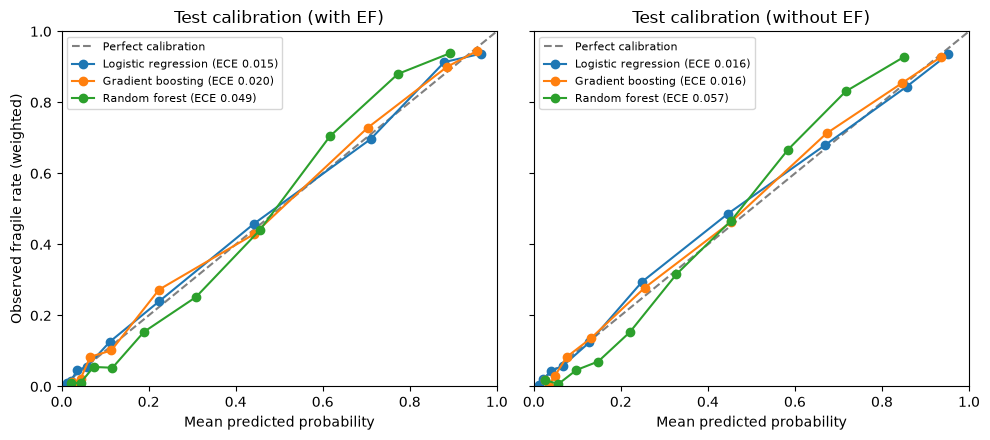

In [8]:
calibration_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, label in zip(axes, ["with EF", "without EF"]):
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    for name in MODELS:
        table, ece = weighted_calibration(y_test, predictions[(name, label)], w_test)
        ax.plot(table["mean_predicted"], table["observed_rate"], "o-",
                label=f"{name} (ECE {ece:.3f})")
        calibration_rows.append(table.reset_index().assign(model=name, features=label))
    ax.set(xlabel="Mean predicted probability", title=f"Test calibration ({label})",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Observed fragile rate (weighted)")
fig.tight_layout()
plt.show()

calibration_bins = pd.concat(calibration_rows, ignore_index=True)
calibration_bins["bin"] = calibration_bins["bin"].astype(str)

## 8. Bootstrap confidence intervals

Resample test respondents with replacement (predictions stay fixed) to see whether the differences between models are larger than test-set noise. Intervals are 2.5th to 97.5th percentiles. The paired differences use the same resample for both models.

In [9]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
y_arr, w_arr = y_test.to_numpy(), w_test.to_numpy()
p_arr = {name: predictions[(name, "with EF")].to_numpy() for name in MODELS}
BOOT_METRICS = {
    "ROC AUC": lambda y, p, w: roc_auc_score(y, p, sample_weight=w),
    "Brier": lambda y, p, w: brier_score_loss(y, p, sample_weight=w),
    "ECE": lambda y, p, w: weighted_calibration(y, p, w)[1],
}

draws = []
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for name in MODELS:
        for metric, fn in BOOT_METRICS.items():
            draws.append({"draw": b, "model": name, "metric": metric,
                          "value": fn(y_arr[idx], p_arr[name][idx], w_arr[idx])})
draws = pd.DataFrame(draws)

intervals = (draws.groupby(["metric", "model"])["value"]
             .quantile([0.025, 0.975]).unstack()
             .rename(columns={0.025: "lower", 0.975: "upper"}))
point = metrics[metrics["features"] == "with EF"].set_index("model")
intervals["estimate"] = [point.loc[m, metric] for metric, m in intervals.index]
display(intervals[["estimate", "lower", "upper"]].round(3))

wide = draws.pivot_table(index=["draw", "metric"], columns="model", values="value")
pairs = [("Gradient boosting", "Logistic regression"),
         ("Gradient boosting", "Random forest"),
         ("Logistic regression", "Random forest")]
paired = []
for a, b in pairs:
    for metric in BOOT_METRICS:
        diff = (wide[a] - wide[b]).xs(metric, level="metric")
        paired.append({"comparison": f"{a} - {b}", "metric": metric,
                       "lower": diff.quantile(0.025), "upper": diff.quantile(0.975),
                       "share of draws > 0": (diff > 0).mean()})
paired = pd.DataFrame(paired)
display(paired.set_index(["metric", "comparison"]).round(3))

estimate  lower  upper
metric  model                                      
Brier   Gradient boosting       0.101  0.092  0.108
        Logistic regression     0.103  0.094  0.111
        Random forest           0.111  0.104  0.118
ECE     Gradient boosting       0.020  0.014  0.034
        Logistic regression     0.015  0.013  0.033
        Random forest           0.049  0.039  0.063
ROC AUC Gradient boosting       0.929  0.919  0.939
        Logistic regression     0.925  0.914  0.937
        Random forest           0.919  0.907  0.931

,,lower,upper,share of draws > 0
metric,comparison,,,
ROC AUC,Gradient boosting - Logistic regression,-0.000,0.007,0.970
Brier,Gradient boosting - Logistic regression,-0.005,0.001,0.116
ECE,Gradient boosting - Logistic regression,-0.011,0.013,0.616
ROC AUC,Gradient boosting - Random forest,0.006,0.014,1.000
Brier,Gradient boosting - Random forest,-0.014,-0.008,0.000
ECE,Gradient boosting - Random forest,-0.043,-0.012,0.000
ROC AUC,Logistic regression - Random forest,0.002,0.011,0.998
Brier,Logistic regression - Random forest,-0.013,-0.005,0.000
ECE,Logistic regression - Random forest,-0.043,-0.012,0.000


## 9. Save outputs for Task 4

In [10]:
OUT = Path("../outputs/task3") if Path("../data/processed").exists() else Path("outputs/task3")
OUT.mkdir(parents=True, exist_ok=True)

slug = {"Logistic regression": "lr", "Gradient boosting": "gb", "Random forest": "rf"}
saved = test[[ID, TARGET, WEIGHT]].rename(columns={TARGET: "actual_fragile"})
for (name, label), p in predictions.items():
    suffix = "" if label == "with EF" else "_no_ef"
    saved[f"p_{slug[name]}{suffix}"] = p
saved.to_csv(OUT / "test_predictions.csv", index=False)
metrics.to_csv(OUT / "metrics.csv", index=False)
calibration_bins.to_csv(OUT / "calibration_bins.csv", index=False)
intervals.reset_index().to_csv(OUT / "bootstrap_intervals.csv", index=False)
paired.to_csv(OUT / "bootstrap_paired_differences.csv", index=False)
print("Saved to", OUT.resolve())
for path in sorted(OUT.glob("*.csv")):
    print(" ", path.name)

Saved to C:\Users\Ansa\breakthrutech\Thrivent-1A-financial-resilience-map\outputs\task3
  bootstrap_intervals.csv
  bootstrap_paired_differences.csv
  calibration_bins.csv
  metrics.csv
  test_predictions.csv


## 10. SHAP explanations (to do)

Planned: `TreeExplainer` for gradient boosting and random forest, `LinearExplainer` for logistic regression (background = a sample of training rows). Sum one-hot SHAP values back to each survey question, rank questions by weighted mean |SHAP|, and compare rankings across models. Save to `outputs/task3/shap_importance.csv`.

The fitted pipelines are in `fitted[(model name, "with EF")]`.